**Daily Weather Time Series Data - Delhi, India**

https://www.kaggle.com/datasets/yug201/daily-climate-time-series-data-delhi-india?select=kaggel_weather_2013_to_2024.csv

**Тема:** Прогнозування часових рядів на основі кліматичних даних

**Мета роботи:**
Навчитися виконувати аналіз часових рядів, проводити дослідницький аналіз даних (EDA), визначати автокореляційні залежності, будувати моделі прогнозування та оцінювати їхню точність.

**Вихідні дані**

Для виконання роботи використовується датасет Daily Climate Time Series Data (Delhi, India) з платформи Kaggle, який містить щоденні кліматичні показники (температура, вологість, опади тощо) за кілька років.


1. Завантажити датасет з Kaggle.

2. Імпортувати дані у середовище Python (Jupyter Notebook або Google Colab).

3. Ознайомитися зі структурою датасету (head(), info(), describe()).

4. Попередня обробка даних

-Перетворити колонку з датою у формат datetime.

-Відсортувати дані за датою.

-Встановити дату як індекс часового ряду.

-Перевірити наявність пропущених значень та за необхідності обробити їх.

5. Дослідницький аналіз даних (EDA)

-Побудувати графік зміни температури у часі.

-Побудувати ковзне середнє значення температури.

-Побудувати гістограму розподілу температури.

-Побудувати boxplot для виявлення можливих викидів.

-Аналіз автокореляції

Побудувати графік автокореляційної функції (ACF).

Побудувати графік часткової автокореляції (PACF).

-Проаналізувати залежність значень часового ряду від попередніх періодів.

6.Підготовка даних для моделювання

-Розділити дані на тренувальну та тестову вибірки (наприклад, 80% / 20%).

7. Побудувати щонайменше три моделі прогнозування:

-ARIMA (класична статистична модель);

-Prophet (модель прогнозування часових рядів від Meta);

-LSTM (нейронна мережа для послідовних даних).

8. Оцінка моделей
Для кожної моделі обчислити метрики:

-MAE (Mean Absolute Error)

-RMSE (Root Mean Squared Error)

-MAPE (Mean Absolute Percentage Error)

8.Візуалізація результатів

-Побудувати графіки прогнозованих та фактичних значень.

-Побудувати порівняльний графік прогнозів усіх моделей.

-Порівняння моделей

-Створити таблицю з метриками точності.

9.Визначити модель, яка показала найкращий результат.

In [4]:
# Імпорт необхідних бібліотек
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


In [7]:
# Виберіть CSV-файл із комп'ютера у вікні, яке відкриється.
from google.colab import files
import io
import pandas as pd

uploaded = files.upload()

if not uploaded:
    raise FileNotFoundError("Файл не вибрано. Запустіть клітинку ще раз.")

CSV_PATH = next(iter(uploaded.keys()))
print("Вибраний файл:", CSV_PATH)


Saving kaggel_weather_2013_to_2024.csv to kaggel_weather_2013_to_2024.csv
Вибраний файл: kaggel_weather_2013_to_2024.csv


In [10]:
# Зчитайте датасет у DataFrame та перегляньте дані
from pathlib import Path

if not Path(CSV_PATH).exists():
    # Спроба знайти будь-який CSV у поточній папці
    csv_files = list(Path(".").glob("*.csv"))
    if len(csv_files) == 1:
        CSV_PATH = str(csv_files[0])
        print(f"Використовую знайдений файл: {CSV_PATH}")
    else:
        raise FileNotFoundError(
            f"Не знайдено {CSV_PATH}. Завантажте CSV з Kaggle у папку з ноутбуком "
            "або вкажіть правильний шлях у змінній CSV_PATH."
        )

df = pd.read_csv(CSV_PATH)
display(df.head())
print("Розмір датасету:", df.shape)
print("\nІнформація про стовпці:")
df.info()
display(df.describe(include="all").T)

,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
0,0,4/14/2013,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
1,1,4/15/2013,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2,2,4/16/2013,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
3,3,4/17/2013,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
4,4,4/18/2013,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


Розмір датасету: (3557, 29)

Інформація про стовпці:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3557 entries, 0 to 3556
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             3557 non-null   int64  
 1   DATE                   3557 non-null   object 
 2   tempmax                3557 non-null   float64
 3   tempmin                3557 non-null   float64
 4   temp                   3557 non-null   float64
 5   feelslikemax           3557 non-null   float64
 6   feelslikemin           3557 non-null   float64
 7   feelslike              3557 non-null   float64
 8   humidity               3557 non-null   float64
 9   precip                 3557 non-null   float64
 10  precipprob             3557 non-null   int64  
 11  precipcover            3557 non-null   float64
 12  windspeed              3557 non-null   float64
 13  sealevelpressure       3557 non-null   float64
 14  con

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,3557.0,NaN,NaN,NaN,1778.0,1026.961781,0.0,889.0,1778.0,2667.0,3556.0
DATE,3557,3556,5/1/2022,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tempmax,3557.0,NaN,NaN,NaN,31.367501,7.073934,9.1,26.4,33.0,36.0,47.9
tempmin,3557.0,NaN,NaN,NaN,20.076132,7.568531,2.0,13.0,22.0,26.9,34.8
temp,3557.0,NaN,NaN,NaN,25.403374,7.325541,6.5,19.1,27.7,31.0,39.5
feelslikemax,3557.0,NaN,NaN,NaN,34.28018,9.651743,7.9,26.3,35.4,42.7,57.7
feelslikemin,3557.0,NaN,NaN,NaN,20.938769,9.004827,0.3,13.0,22.0,28.0,41.1
feelslike,3557.0,NaN,NaN,NaN,27.306803,9.301636,5.7,19.1,28.4,35.4,47.0
humidity,3557.0,NaN,NaN,NaN,63.75544,18.129251,16.1,53.0,65.8,76.9,99.3
precip,3557.0,NaN,NaN,NaN,2.459033,10.636255,0.0,0.0,0.0,0.0,203.047


Підготовка даних

In [11]:
# Попередня обробка: дата, сортування, індекс та пропущені значення
# Знаходимо колонку дати незалежно від регістру назви
date_candidates = [c for c in df.columns if c.strip().lower() in
                   ["date", "datetime", "time", "day", "дата"]]
if not date_candidates:
    date_candidates = [c for c in df.columns if "date" in c.lower() or "time" in c.lower()]
if not date_candidates:
    raise ValueError(f"Не знайдено колонку з датою. Наявні колонки: {list(df.columns)}")
DATE_COL = date_candidates[0]

df[DATE_COL] = pd.to_datetime(df[DATE_COL], errors="coerce")
df = df.dropna(subset=[DATE_COL]).sort_values(DATE_COL)

# Визначаємо колонку температури за типовими назвами; якщо їх немає — просимо вибрати вручну
temperature_candidates = [c for c in df.columns if any(k in c.lower()
    for k in ["temp", "temperature", "температур"])]
if not temperature_candidates:
    raise ValueError(
        "Не вдалося автоматично визначити колонку температури. "
        f"Наявні колонки: {list(df.columns)}. Вкажіть назву в TEMP_COL вручну."
    )
TEMP_COL = next((c for c in temperature_candidates if "mean" in c.lower()), temperature_candidates[0])

# Зайві колонки з повністю порожніми значеннями видаляємо
df = df.dropna(axis=1, how="all")
df = df.set_index(DATE_COL)
df = df[~df.index.duplicated(keep="first")]

# Перетворюємо температуру на числовий тип та заповнюємо пропуски інтерполяцією за часом
df[TEMP_COL] = pd.to_numeric(df[TEMP_COL], errors="coerce")
df[TEMP_COL] = df[TEMP_COL].interpolate(method="time").ffill().bfill()
df = df.dropna(subset=[TEMP_COL])

print("Колонка дати:", DATE_COL)
print("Цільова колонка (температура):", TEMP_COL)
print("Період:", df.index.min(), "—", df.index.max())
display(df.head())


Колонка дати: DATE
Цільова колонка (температура): tempmax
Період: 2013-04-14 00:00:00 — 2024-11-30 00:00:00


,Unnamed: 0,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
DATE,,,,,,,,,,,,,,,,,,,,,
2013-04-14,0,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,100,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
2013-04-15,1,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,0,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2013-04-16,2,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,0,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
2013-04-17,3,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,0,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
2013-04-18,4,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,0,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


In [12]:
# Перегляньте інформацію про структуру датасету
df.info()
display(df.describe())

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3556 entries, 2013-04-14 to 2024-11-30
Data columns (total 28 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             3556 non-null   int64  
 1   tempmax                3556 non-null   float64
 2   tempmin                3556 non-null   float64
 3   temp                   3556 non-null   float64
 4   feelslikemax           3556 non-null   float64
 5   feelslikemin           3556 non-null   float64
 6   feelslike              3556 non-null   float64
 7   humidity               3556 non-null   float64
 8   precip                 3556 non-null   float64
 9   precipprob             3556 non-null   int64  
 10  precipcover            3556 non-null   float64
 11  windspeed              3556 non-null   float64
 12  sealevelpressure       3556 non-null   float64
 13  conditions             3556 non-null   object 
 14  Year                   3556 non-null  

,Unnamed: 0,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
count,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,...,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000
mean,1777.764904,31.365073,20.073847,25.400984,34.277925,20.936699,27.304921,63.764258,2.459725,23.143982,...,19.268560,26.868673,1919.270807,1241.006375,1554.504165,2137.916848,1300.059699,1697.056932,11.291226,195.599722
std,1027.010475,7.073447,7.568369,7.325185,9.652163,9.005246,9.302266,18.124170,10.637671,42.181212,...,3.219426,14.911475,525.858317,580.762376,539.244300,839.882256,692.667235,754.684620,3.622730,55.575946
min,0.000000,9.100000,2.000000,6.500000,7.900000,0.300000,5.700000,16.100000,0.000000,0.000000,...,13.000000,1.000000,686.400000,181.200000,586.560000,636.480000,18.960000,560.880000,1.500000,73.465023
25%,888.750000,26.400000,13.000000,19.100000,26.300000,13.000000,19.100000,53.000000,0.000000,0.000000,...,17.000000,14.000000,1542.450000,759.282500,1120.135000,1534.475000,751.912500,1113.712500,8.300000,164.448043
50%,1777.500000,32.950000,22.000000,27.700000,35.350000,22.000000,28.400000,65.800000,0.000000,0.000000,...,20.000000,27.000000,1823.440000,1078.520000,1420.300000,1845.635000,1081.015000,1423.715000,11.600000,180.579833
75%,2667.250000,36.000000,26.900000,31.000000,42.700000,28.000000,35.400000,76.900000,0.000000,0.000000,...,22.000000,40.000000,2341.527500,1752.770000,2035.927500,2764.697500,1864.350000,2315.295000,14.100000,233.701315
max,3556.000000,47.900000,34.800000,39.500000,57.700000,41.100000,47.000000,99.300000,203.047000,100.000000,...,24.000000,53.000000,3180.720000,2581.600000,2710.680000,4617.200000,3273.740000,3727.950000,20.600000,352.198303


In [13]:
# Перевірте наявність пропущених значень
missing = df.isna().sum().sort_values(ascending=False)
display(missing.to_frame("Кількість пропусків"))
print("Пропущених значень у температурі:", int(df[TEMP_COL].isna().sum()))

,Кількість пропусків
Unnamed: 0,0
tempmax,0
tempmin,0
temp,0
feelslikemax,0
feelslikemin,0
feelslike,0
humidity,0
precip,0
precipprob,0


Пропущених значень у температурі: 0


Графік температури

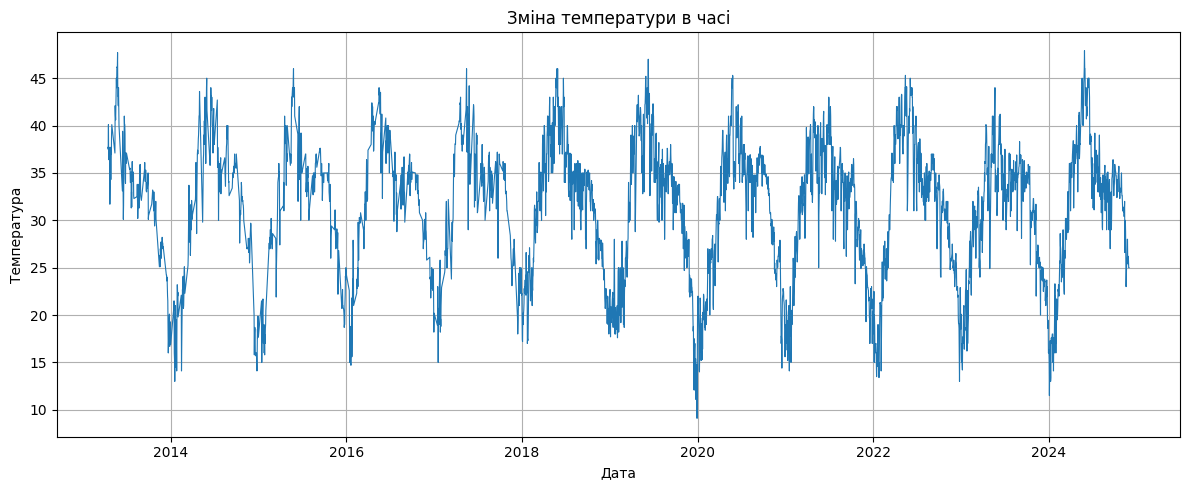

In [14]:
# Побудуйте графік зміни температури у часі
plt.figure()
plt.plot(df.index, df[TEMP_COL], linewidth=0.8)
plt.title("Зміна температури в часі")
plt.xlabel("Дата")
plt.ylabel("Температура")
plt.tight_layout()
plt.show()


Ковзне середнє

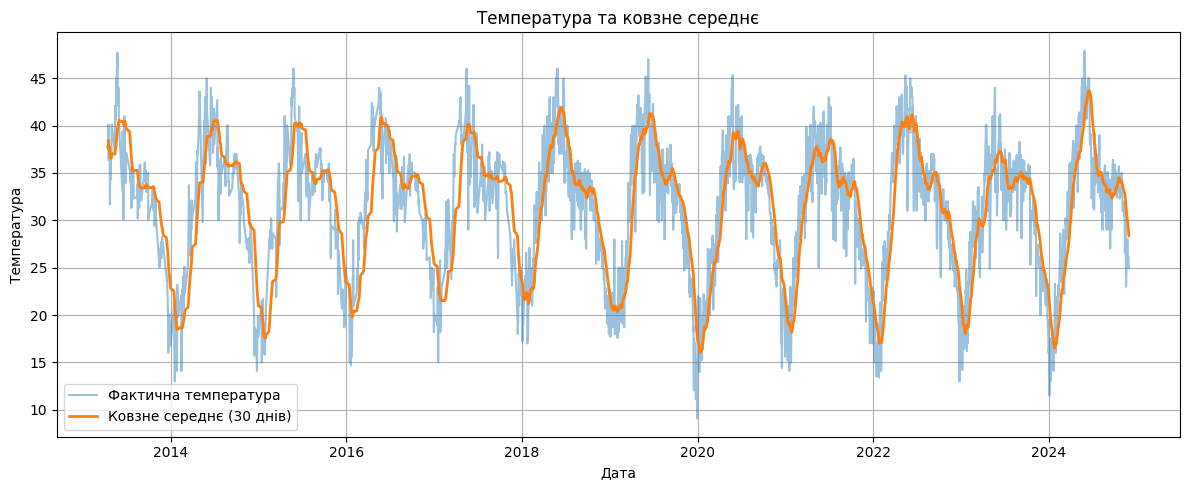

In [15]:
# Обчисліть та візуалізуйте ковзне середнє температури
df["Temperature_MA30"] = df[TEMP_COL].rolling(window=30, min_periods=1).mean()
plt.figure()
plt.plot(df.index, df[TEMP_COL], alpha=0.45, label="Фактична температура")
plt.plot(df.index, df["Temperature_MA30"], linewidth=2, label="Ковзне середнє (30 днів)")
plt.title("Температура та ковзне середнє")
plt.xlabel("Дата")
plt.ylabel("Температура")
plt.legend()
plt.tight_layout()
plt.show()

Розподіл температури

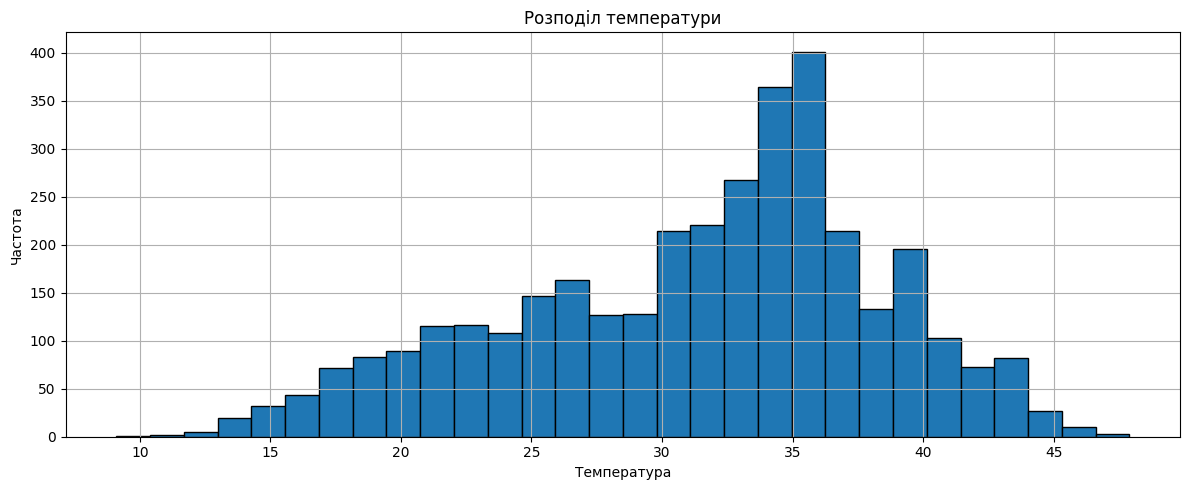

In [16]:
# Побудуйте гістограму розподілу температури
plt.figure()
plt.hist(df[TEMP_COL].dropna(), bins=30, edgecolor="black")
plt.title("Розподіл температури")
plt.xlabel("Температура")
plt.ylabel("Частота")
plt.tight_layout()
plt.show()


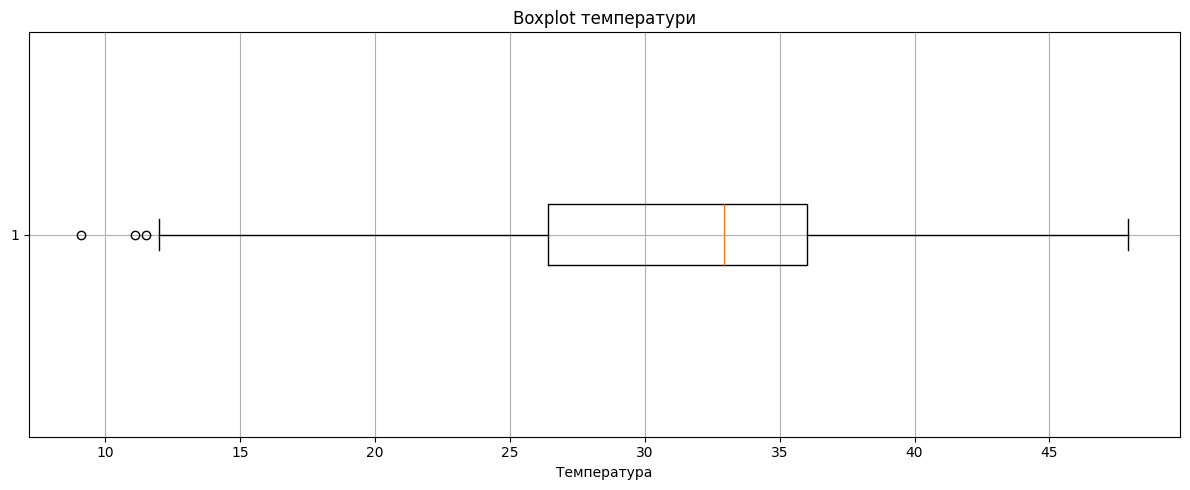

Можливі викиди за правилом 1.5*IQR: 3


In [17]:
# Побудуйте boxplot температури для аналізу викидів
plt.figure()
plt.boxplot(df[TEMP_COL].dropna(), vert=False)
plt.title("Boxplot температури")
plt.xlabel("Температура")
plt.tight_layout()
plt.show()

q1, q3 = df[TEMP_COL].quantile([0.25, 0.75])
iqr = q3 - q1
outliers = df[(df[TEMP_COL] < q1 - 1.5 * iqr) | (df[TEMP_COL] > q3 + 1.5 * iqr)]
print(f"Можливі викиди за правилом 1.5*IQR: {len(outliers)}")

Аналіз автокореляції
ACF

PACF

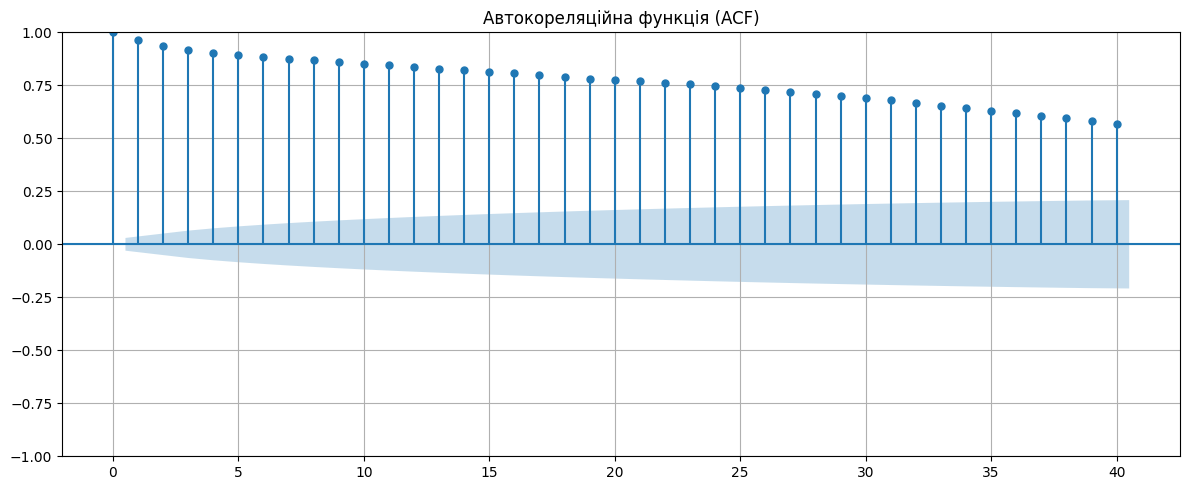

In [18]:
# Побудуйте графік автокореляційної функції (ACF)
series = df[TEMP_COL].asfreq(pd.infer_freq(df.index) or "D")
series = series.interpolate(method="time").ffill().bfill()
plot_acf(series.dropna(), lags=min(40, max(1, len(series)//2 - 1)))
plt.title("Автокореляційна функція (ACF)")
plt.tight_layout()
plt.show()

Автокореляційна функція (ACF) використовується для аналізу залежності значень часового ряду від його попередніх значень. Вона відображає ступінь кореляції між значенням показника у певний момент часу та значеннями цього самого показника у попередні моменти часу, які називаються лагами. Побудова графіка автокореляційної функції дозволяє виявити, чи існує статистично значуща залежність між поточним значенням ряду та його попередніми спостереженнями. На такому графіку по горизонтальній осі відкладаються лаги, тобто кількість часових кроків назад, а по вертикальній — значення коефіцієнта автокореляції. Аналіз графіка ACF дає можливість виявити наявність тренду, сезонності або інших закономірностей у часовому ряді, а також використовується для визначення параметрів статистичних моделей прогнозування, зокрема моделі ARIMA.

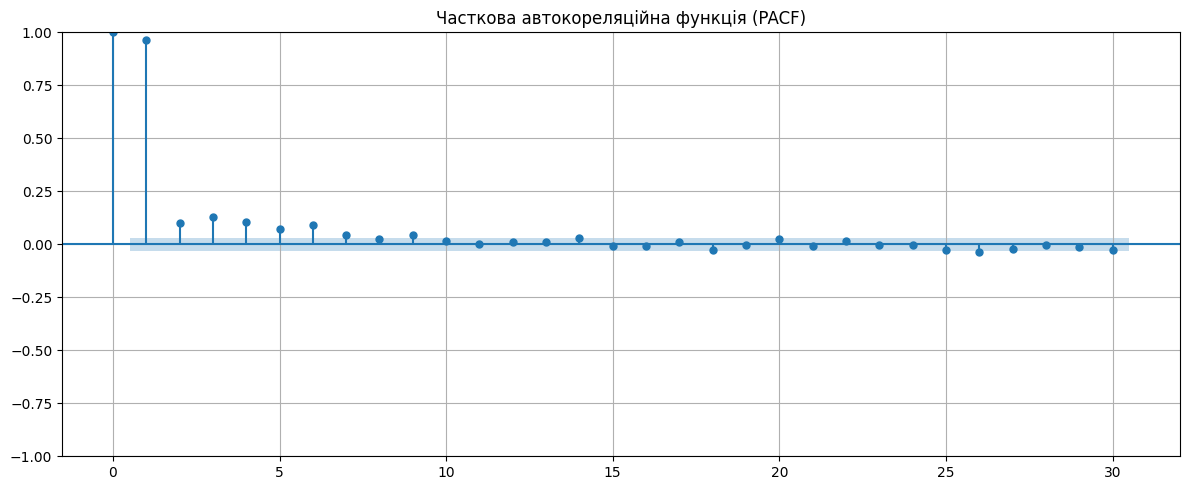

In [19]:
# Побудуйте графік часткової автокореляційної функції (PACF)
series_clean = series.dropna()
pacf_lags = min(30, max(1, len(series_clean)//2 - 1))
plot_pacf(series_clean, lags=pacf_lags, method="ywm")
plt.title("Часткова автокореляційна функція (PACF)")
plt.tight_layout()
plt.show()

Часткова автокореляційна функція (PACF) застосовується для більш точного визначення залежності між значеннями часового ряду. На відміну від звичайної автокореляційної функції, PACF вимірює кореляцію між значенням ряду у певний момент часу та значенням у попередній момент часу з конкретним лагом, усуваючи вплив усіх проміжних лагів. Таким чином, часткова автокореляція показує «чисту» залежність між двома спостереженнями часового ряду. Побудова графіка PACF дозволяє визначити, які саме лаги мають статистично значущий вплив на значення ряду. Це є важливим етапом під час побудови моделей прогнозування часових рядів, оскільки аналіз графіка часткової автокореляції використовується для визначення порядку авторегресійної складової моделі, зокрема параметра
𝑝
p у моделі ARIMA.

In [20]:
# Сформуйте цільовий часовий ряд та розділіть його на train/test у часовому порядку
y = df[TEMP_COL].astype(float).dropna()
split_idx = int(len(y) * 0.8)
train, test = y.iloc[:split_idx], y.iloc[split_idx:]
print(f"Усього спостережень: {len(y)}")
print(f"Train: {len(train)} ({len(train)/len(y):.1%})")
print(f"Test:  {len(test)} ({len(test)/len(y):.1%})")
print("Train:", train.index.min(), "—", train.index.max())
print("Test:", test.index.min(), "—", test.index.max())

Усього спостережень: 3556
Train: 2844 (80.0%)
Test:  712 (20.0%)
Train: 2013-04-14 00:00:00 — 2022-12-19 00:00:00
Test: 2022-12-20 00:00:00 — 2024-11-30 00:00:00


ARIMA

https://developer.ibm.com/tutorials/awb-arima-models-in-python/

In [23]:
# Побудуйте та навчіть модель ARIMA. Отримайте прогноз для тестової вибірки

from statsmodels.tsa.arima.model import ARIMA
import pandas as pd
import numpy as np

train_arima = pd.Series(
    train.to_numpy(),
    index=pd.RangeIndex(start=0, stop=len(train))
)

arima_model = ARIMA(train_arima, order=(5, 1, 0))
arima_fit = arima_model.fit()

forecast_values = np.asarray(
    arima_fit.forecast(steps=len(test))
)

arima_forecast = pd.Series(
    forecast_values,
    index=test.index,
    name="ARIMA"
)

display(arima_forecast.head())


,ARIMA
DATE,
2022-12-20,22.125385
2022-12-21,22.262823
2022-12-22,22.327750
2022-12-23,22.371180
2022-12-24,22.412602


In [24]:
# Виведіть статистичний звіт навченої ARIMA-моделі
print(arima_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 2844
Model:                 ARIMA(5, 1, 0)   Log Likelihood               -6109.741
Date:                Fri, 23 Oct 2026   AIC                          12231.482
Time:                        21:25:55   BIC                          12267.197
Sample:                             0   HQIC                         12244.364
                               - 2844                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.1819      0.015    -11.893      0.000      -0.212      -0.152
ar.L2         -0.2015      0.018    -11.131      0.000      -0.237      -0.166
ar.L3         -0.1589      0.019     -8.184      0.0

сигма 2 : це представляє дисперсію залишкових значень, чим менше, тим краще

логарифмічна правдоподібність : це оцінка максимальної правдоподібності для моделі ARIMA, чим вище, тим краще

aic : міра ступеню відповідності та економності моделі, чим нижче, тим краще

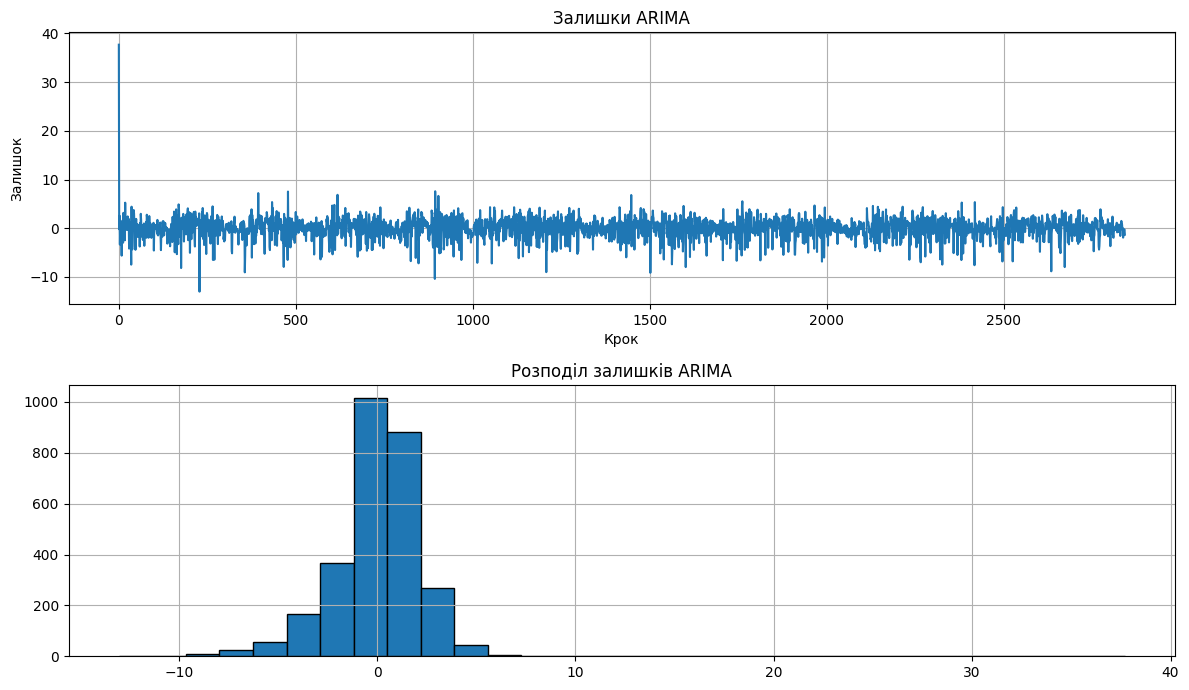

Середнє залишків: 0.0038


In [25]:
# Проаналізуйте залишки ARIMA-моделі та побудуйте відповідні графіки
residuals = pd.Series(arima_fit.resid).dropna()
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
axes[0].plot(residuals)
axes[0].set_title("Залишки ARIMA")
axes[0].set_xlabel("Крок")
axes[0].set_ylabel("Залишок")
axes[1].hist(residuals, bins=30, edgecolor="black")
axes[1].set_title("Розподіл залишків ARIMA")
plt.tight_layout()
plt.show()
print("Середнє залишків:", round(float(residuals.mean()), 4))

In [26]:
# Реалізуйте MAPE та обчисліть MAE, RMSE, MAPE для ARIMA
def calculate_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    nonzero = np.abs(actual) > 1e-8
    mape = np.mean(np.abs((actual[nonzero] - predicted[nonzero]) / actual[nonzero])) * 100 if nonzero.any() else np.nan
    return {"MAE": mae, "RMSE": rmse, "MAPE (%)": mape}

arima_metrics = calculate_metrics(test, arima_forecast)
print(arima_metrics)

{'MAE': 9.74968224098972, 'RMSE': np.float64(11.125210873165672), 'MAPE (%)': np.float64(29.68944061697035)}


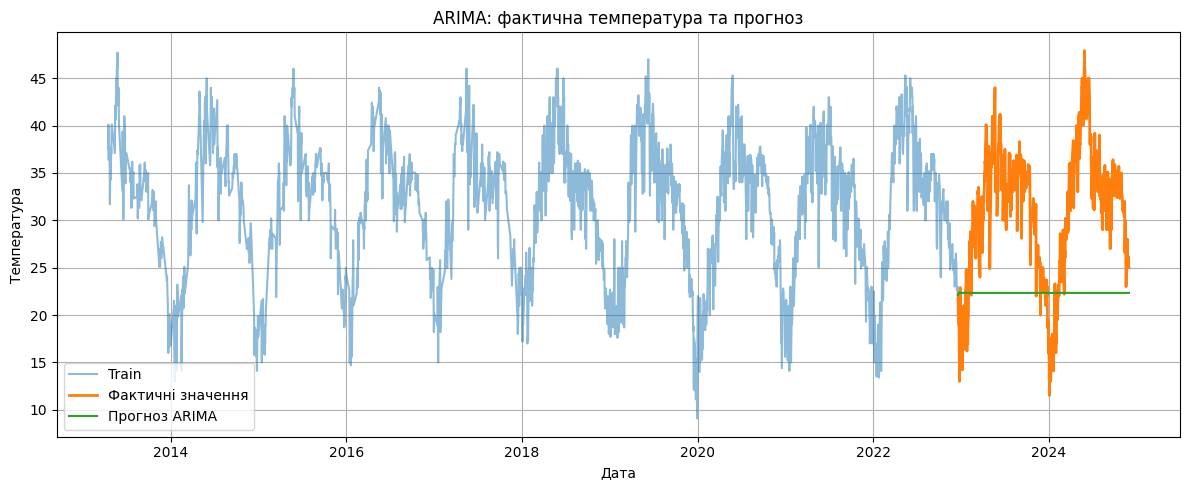

In [27]:
# Візуалізуйте фактичні значення та прогноз ARIMA
plt.figure()
plt.plot(train.index, train, label="Train", alpha=0.5)
plt.plot(test.index, test, label="Фактичні значення", linewidth=2)
plt.plot(arima_forecast.index, arima_forecast, label="Прогноз ARIMA")
plt.title("ARIMA: фактична температура та прогноз")
plt.xlabel("Дата")
plt.ylabel("Температура")
plt.legend()
plt.tight_layout()
plt.show()

PROPHET

https://facebook.github.io/prophet/docs/quick_start.html

In [28]:
# Підготуйте дані у форматі, необхідному для Prophet
prophet_train = pd.DataFrame({"ds": train.index, "y": train.values})
prophet_test = pd.DataFrame({"ds": test.index, "y": test.values})
display(prophet_train.head())

,ds,y
0,2013-04-14,37.7
1,2013-04-15,37.5
2,2013-04-16,40.1
3,2013-04-17,36.4
4,2013-04-18,37.5


In [29]:
# Створіть та навчіть модель Prophet
from prophet import Prophet

prophet_model = Prophet()
prophet_model.fit(prophet_train)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


Прогноз

In [30]:
# Побудуйте прогноз Prophet для тестового періоду
prophet_future = pd.DataFrame({"ds": test.index})
prophet_result = prophet_model.predict(prophet_future)
prophet_forecast = pd.Series(prophet_result["yhat"].to_numpy(), index=test.index, name="Prophet")
display(prophet_result[["ds", "yhat", "yhat_lower", "yhat_upper"]].head())

,ds,yhat,yhat_lower,yhat_upper
0,2022-12-20,20.334124,16.836283,23.782831
1,2022-12-21,20.126072,16.540335,23.405388
2,2022-12-22,19.909275,16.440909,23.253135
3,2022-12-23,19.722304,16.393117,23.266161
4,2022-12-24,19.512794,16.147189,22.713165


In [31]:
# Обчисліть MAE, RMSE, MAPE для Prophet
prophet_metrics = calculate_metrics(test, prophet_forecast)
print(prophet_metrics)

{'MAE': 2.3323811894593423, 'RMSE': np.float64(3.024113315929569), 'MAPE (%)': np.float64(8.245993781417932)}


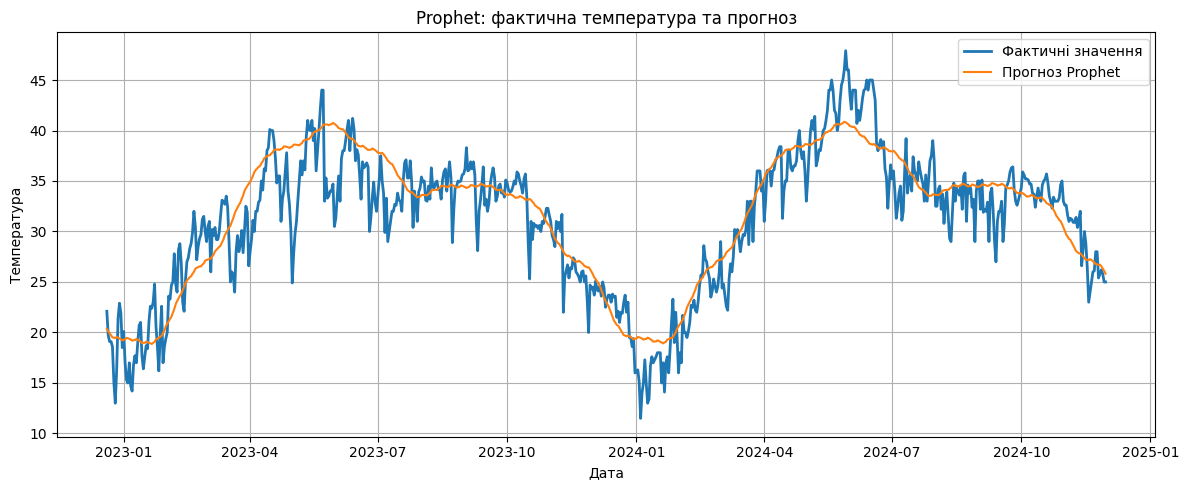

In [32]:
# Візуалізуйте фактичні значення та прогноз Prophet
plt.figure()
plt.plot(test.index, test, label="Фактичні значення", linewidth=2)
plt.plot(prophet_forecast.index, prophet_forecast, label="Прогноз Prophet")
plt.title("Prophet: фактична температура та прогноз")
plt.xlabel("Дата")
plt.ylabel("Температура")
plt.legend()
plt.tight_layout()
plt.show()

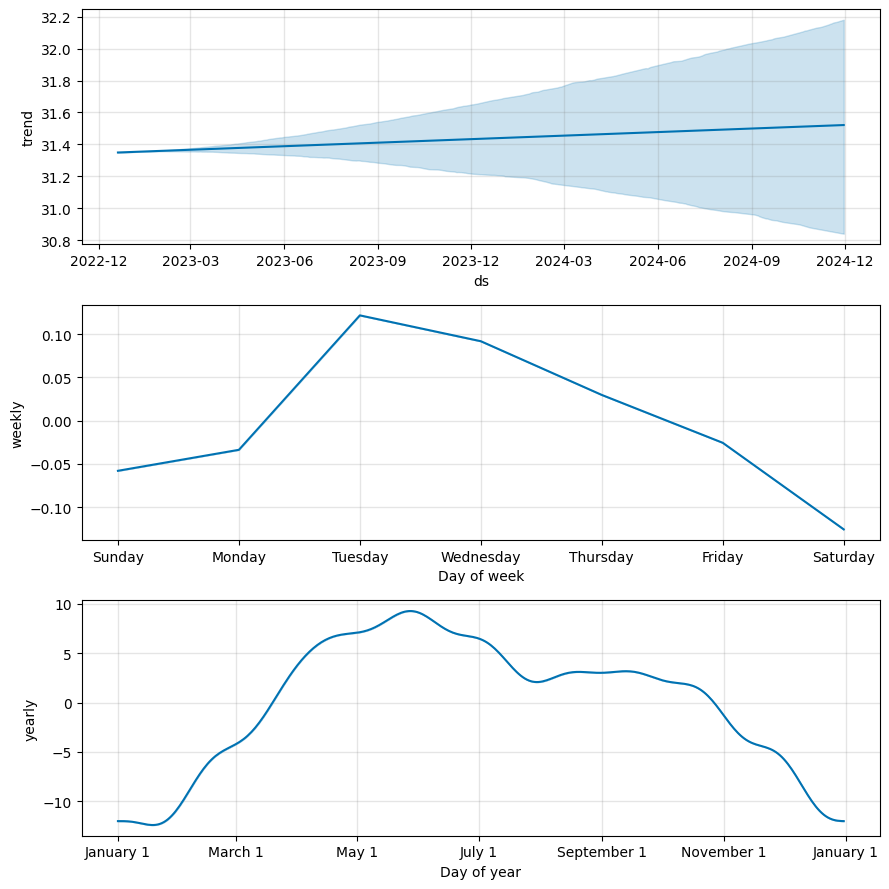

In [33]:
# Побудуйте компоненти моделі Prophet
prophet_model.plot_components(prophet_result)
plt.tight_layout()
plt.show()

ПІДГОТОВКА ДАНИХ ДЛЯ LSTM

In [35]:
# Масштабуйте часовий ряд та сформуйте послідовності для LSTM
from sklearn.preprocessing import MinMaxScaler

LOOKBACK = 30
scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(train.to_numpy().reshape(-1, 1))

all_scaled = scaler.transform(y.to_numpy().reshape(-1, 1))

def make_sequences(values, lookback):
    X_seq, y_seq = [], []
    for i in range(lookback, len(values)):
        X_seq.append(values[i-lookback:i, 0])
        y_seq.append(values[i, 0])
    return np.array(X_seq), np.array(y_seq)

X_all, y_all = make_sequences(all_scaled, LOOKBACK)

target_positions = np.arange(LOOKBACK, len(y))
train_mask = target_positions < split_idx
test_mask = target_positions >= split_idx
X_train_lstm = X_all[train_mask].reshape(-1, LOOKBACK, 1)
y_train_lstm = y_all[train_mask]
X_test_lstm = X_all[test_mask].reshape(-1, LOOKBACK, 1)
y_test_lstm = y_all[test_mask]
print("X train:", X_train_lstm.shape, "X test:", X_test_lstm.shape)

X train: (2814, 30, 1) X test: (712, 30, 1)


In [36]:
# Розділіть послідовності на тренувальну та тестову вибірки без перемішування
assert len(X_train_lstm) > 0 and len(X_test_lstm) > 0
print("Навчальні послідовності:", len(X_train_lstm))
print("Тестові послідовності:", len(X_test_lstm))
print("Дані не перемішуються: використано часовий порядок.")

Навчальні послідовності: 2814
Тестові послідовності: 712
Дані не перемішуються: використано часовий порядок.


In [37]:
# Побудуйте архітектуру LSTM-моделі та скомпілюйте її
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

lstm_model = Sequential([
    LSTM(50, input_shape=(LOOKBACK, 1)),
    Dropout(0.2),
    Dense(25, activation="relu"),
    Dense(1)
])
lstm_model.compile(optimizer="adam", loss="mean_squared_error")
lstm_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,701 (45.71 KB)

 Trainable params: 11,701 (45.71 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 8s 46ms/step - loss: 0.0373 - val_loss: 0.0082
Epoch 2/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0092 - val_loss: 0.0084
Epoch 3/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - loss: 0.0074 - val_loss: 0.0064
Epoch 4/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0067 - val_loss: 0.0060
Epoch 5/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0065 - val_loss: 0.0073
Epoch 6/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0061 - val_loss: 0.0050
Epoch 7/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0057 - val_loss: 0.0068
Epoch 8/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0056 - val_loss: 0.0057
Epoch 9/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0056 - val_loss: 0.0049
Epoch 10/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0053 - val_loss: 0.0043
Epoch 11/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0051 - val_loss: 0.0055
Epoch 12/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0049 - val

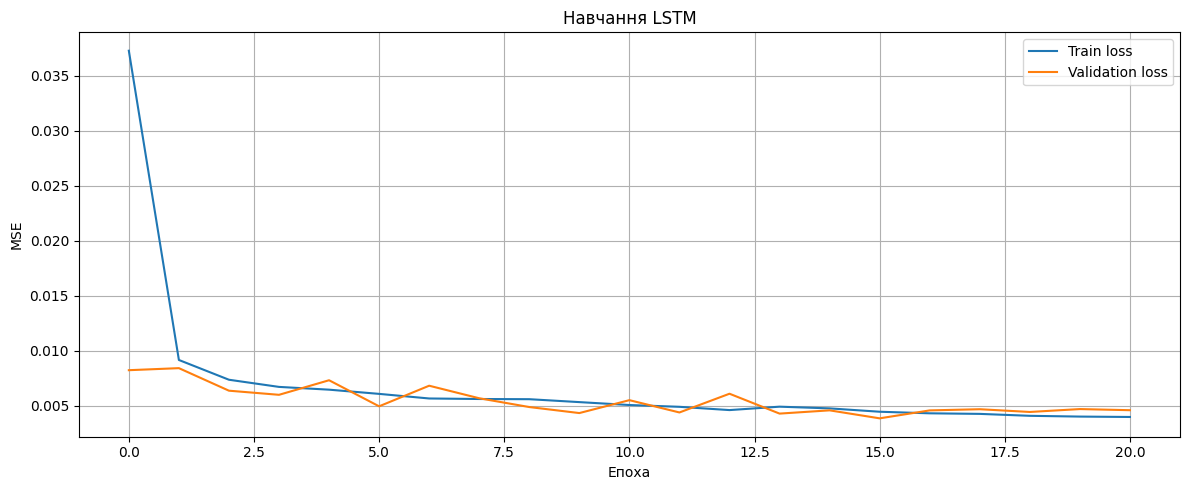

In [38]:
# Навчіть LSTM-модель
early_stop = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
history = lstm_model.fit(
    X_train_lstm, y_train_lstm,
    epochs=30,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

plt.figure()
plt.plot(history.history["loss"], label="Train loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.title("Навчання LSTM")
plt.xlabel("Епоха")
plt.ylabel("MSE")
plt.legend()
plt.tight_layout()
plt.show()

In [39]:
# Виведіть структуру LSTM-моделі
lstm_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 35,105 (137.13 KB)

 Trainable params: 11,701 (45.71 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 23,404 (91.43 KB)

In [40]:
# Отримайте прогноз LSTM та виконайте зворотне масштабування
lstm_scaled_pred = lstm_model.predict(X_test_lstm, verbose=0)
lstm_pred_values = scaler.inverse_transform(lstm_scaled_pred).ravel()
lstm_actual_values = scaler.inverse_transform(y_test_lstm.reshape(-1, 1)).ravel()
lstm_forecast = pd.Series(lstm_pred_values, index=test.index, name="LSTM")
display(lstm_forecast.head())

,LSTM
DATE,
2022-12-20,22.317802
2022-12-21,22.087517
2022-12-22,21.134342
2022-12-23,20.302296
2022-12-24,19.752056


In [41]:
# Сформуйте часові мітки для тестового прогнозу LSTM
lstm_dates = test.index
print("Кількість дат:", len(lstm_dates), "| Кількість прогнозів:", len(lstm_forecast))
assert len(lstm_dates) == len(lstm_forecast)

Кількість дат: 712 | Кількість прогнозів: 712


In [42]:
# Обчисліть MAE, RMSE, MAPE для LSTM
lstm_metrics = calculate_metrics(test, lstm_forecast)
print(lstm_metrics)

{'MAE': 1.8750643183676046, 'RMSE': np.float64(2.3119694035203855), 'MAPE (%)': np.float64(6.3443837034806165)}


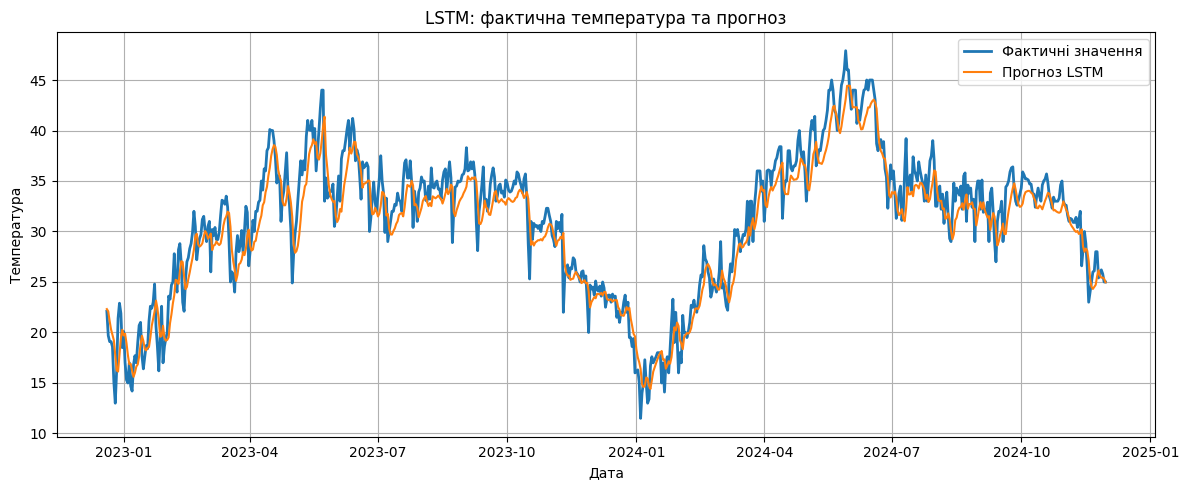

In [43]:
# Візуалізуйте фактичні значення та прогноз LSTM
plt.figure()
plt.plot(test.index, test, label="Фактичні значення", linewidth=2)
plt.plot(lstm_forecast.index, lstm_forecast, label="Прогноз LSTM")
plt.title("LSTM: фактична температура та прогноз")
plt.xlabel("Дата")
plt.ylabel("Температура")
plt.legend()
plt.tight_layout()
plt.show()

Порівняння моделей

,MAE,RMSE,MAPE (%)
LSTM,1.875064,2.311969,6.344384
Prophet,2.332381,3.024113,8.245994
ARIMA,9.749682,11.125211,29.689441


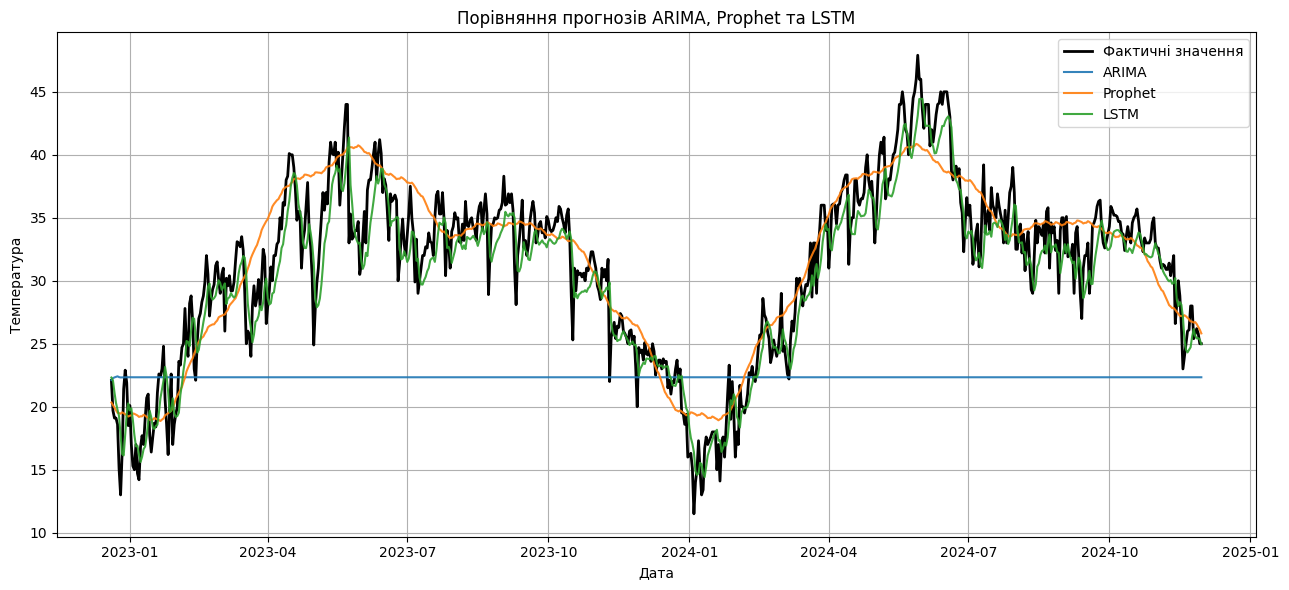

Найкраща модель за RMSE: LSTM
Менші значення MAE, RMSE та MAPE означають точніший прогноз.


In [44]:
# Створіть підсумкову таблицю MAE, RMSE, MAPE для ARIMA, Prophet та LSTM
# Порівняйте моделі за отриманими результатами
comparison = pd.DataFrame(
    {"ARIMA": arima_metrics, "Prophet": prophet_metrics, "LSTM": lstm_metrics}
).T
display(comparison.sort_values("RMSE"))

plt.figure(figsize=(13, 6))
plt.plot(test.index, test, label="Фактичні значення", color="black", linewidth=2)
plt.plot(arima_forecast.index, arima_forecast, label="ARIMA", alpha=0.9)
plt.plot(prophet_forecast.index, prophet_forecast, label="Prophet", alpha=0.9)
plt.plot(lstm_forecast.index, lstm_forecast, label="LSTM", alpha=0.9)
plt.title("Порівняння прогнозів ARIMA, Prophet та LSTM")
plt.xlabel("Дата")
plt.ylabel("Температура")
plt.legend()
plt.tight_layout()
plt.show()

best_model = comparison["RMSE"].idxmin()
print(f"Найкраща модель за RMSE: {best_model}")
print("Менші значення MAE, RMSE та MAPE означають точніший прогноз.")

## Висновок

Сформулюйте висновок за результатами роботи: коротко охарактеризуйте виконаний аналіз, порівняйте моделі ARIMA, Prophet та LSTM за метриками MAE, RMSE і MAPE та зазначте, яка модель продемонструвала найкращу якість прогнозування.
